# 04 · Local Search

Closing the gap for almost nothing. **2-opt** is the single highest-value routing technique:
repeatedly find two edges that cross or waste distance and reverse the segment between them to
uncross them, until no improvement remains. Applied to a nearest-neighbor start it drops a ~20%
tour to within a few percent of optimal — in a fraction of a second. **Or-opt** (relocating short
chains of stops) is its complement.

Each applied move strictly shortens the tour, so the length improves monotonically (asserted in
the test suite).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

from src.evaluation.gap_to_optimal import gap_percent
from src.heuristics.nearest_neighbor import nearest_neighbor_tour
from src.heuristics.or_opt import or_opt
from src.heuristics.two_opt import two_opt, two_opt_steps
from src.ortools_solver.routing import solve_tsp
from src.problems.tsp import generate_tsp_instance, tour_length
from src.reporting import save_figure, save_json
from src.visualisation import plot_tour

SEED = 42
N = 60

## 1. Nearest-neighbor, then 2-opt

The clumsy greedy route next to the same route after 2-opt uncrosses its wasteful edges.

In [2]:
instance = generate_tsp_instance(N, seed=SEED)
_, best_known = solve_tsp(instance.distances, time_limit=5.0)

nn_route = nearest_neighbor_tour(instance.distances)
opt2_route = two_opt(nn_route, instance.distances)
oropt_route = or_opt(opt2_route, instance.distances)

lengths = {
    "nearest_neighbor": tour_length(nn_route, instance.distances),
    "nn_2opt": tour_length(opt2_route, instance.distances),
    "nn_2opt_oropt": tour_length(oropt_route, instance.distances),
    "ortools_best_known": best_known,
}
for name, length in lengths.items():
    print(f"{name:>20}: length {length:7.2f}   gap {gap_percent(length, best_known):5.1f}%")

save_json("04_single_instance", {
    "stops": N, "seed": SEED, "reference": "ortools_5s_best_known",
    "lengths": lengths,
    "gap_percent": {k: gap_percent(v, best_known) for k, v in lengths.items()},
})

    nearest_neighbor: length  702.68   gap  19.9%
             nn_2opt: length  603.82   gap   3.1%
       nn_2opt_oropt: length  597.90   gap   2.1%
  ortools_best_known: length  585.85   gap   0.0%


PosixPath('/workspaces/routing_arena/outputs/data/04_single_instance.json')

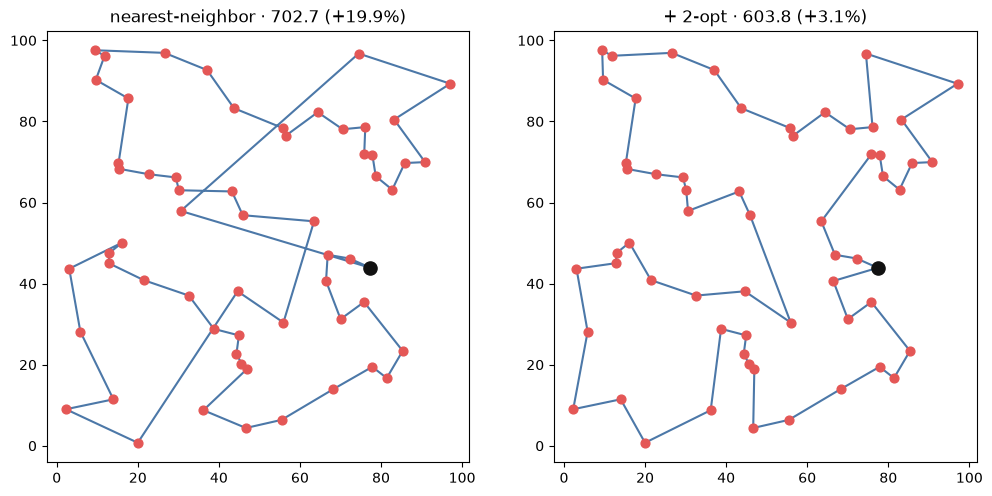

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
plot_tour(instance, nn_route, ax=axes[0],
          title=f"nearest-neighbor · {lengths['nearest_neighbor']:.1f} "
                f"(+{gap_percent(lengths['nearest_neighbor'], best_known):.1f}%)")
plot_tour(instance, opt2_route, ax=axes[1],
          title=f"+ 2-opt · {lengths['nn_2opt']:.1f} "
                f"(+{gap_percent(lengths['nn_2opt'], best_known):.1f}%)")
save_figure(fig, "04_before_after_2opt")
plt.show()

## 2. The tour tightening, swap by swap

`two_opt_steps` yields the tour after every improving move. Its length only ever falls.

22 improving swaps: 702.7 -> 603.8


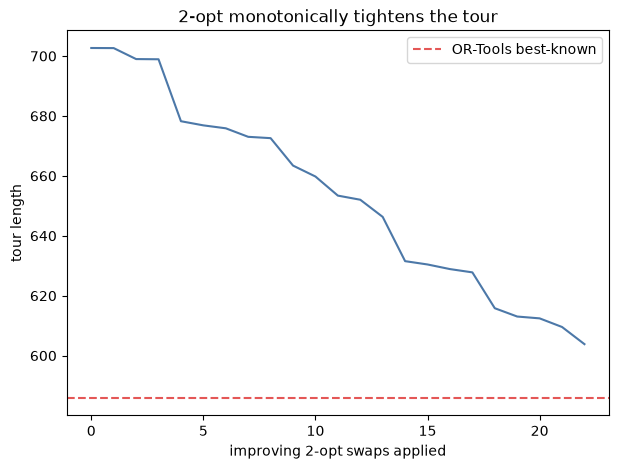

In [4]:
step_lengths = [tour_length(step, instance.distances)
                for step in two_opt_steps(nn_route, instance.distances)]
assert all(b <= a + 1e-9 for a, b in zip(step_lengths, step_lengths[1:]))
print(f"{len(step_lengths) - 1} improving swaps: {step_lengths[0]:.1f} -> {step_lengths[-1]:.1f}")

save_json("04_convergence", {"stops": N, "seed": SEED, "length_per_swap": step_lengths})

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(range(len(step_lengths)), step_lengths, "-", color="#4C78A8")
ax.axhline(best_known, color="#E45756", linestyle="--", label="OR-Tools best-known")
ax.set_xlabel("improving 2-opt swaps applied")
ax.set_ylabel("tour length")
ax.set_title("2-opt monotonically tightens the tour")
ax.legend()
save_figure(fig, "04_convergence")
plt.show()

## 3. The gap, closed, across sizes

Averaged over seeds and sizes: nearest-neighbor alone sits around 20%; 2-opt alone pulls it to a
few percent; or-opt trims a little more. Cheap local search on a cheap construction is most of the
way to optimal.

In [5]:
ladder = [20, 30, 50]
seeds = [0, 1, 2]
stages = ["nearest_neighbor", "nn_2opt", "nn_2opt_oropt"]
gaps = {s: {n: [] for n in ladder} for s in stages}
for n in ladder:
    for seed in seeds:
        inst = generate_tsp_instance(n, seed=seed)
        _, ref = solve_tsp(inst.distances, time_limit=3.0)
        nn = nearest_neighbor_tour(inst.distances)
        t2 = two_opt(nn, inst.distances)
        t3 = or_opt(t2, inst.distances)
        gaps["nearest_neighbor"][n].append(gap_percent(tour_length(nn, inst.distances), ref))
        gaps["nn_2opt"][n].append(gap_percent(tour_length(t2, inst.distances), ref))
        gaps["nn_2opt_oropt"][n].append(gap_percent(tour_length(t3, inst.distances), ref))

mean_gap = {s: {n: float(np.mean(v)) for n, v in sizes.items()} for s, sizes in gaps.items()}
print(f"{'stops':>6} " + " ".join(f"{s:>16}" for s in stages))
for n in ladder:
    print(f"{n:>6} " + " ".join(f"{mean_gap[s][n]:>16.1f}" for s in stages))

save_json("04_gap_study", {"sizes": ladder, "seeds": seeds, "reference": "ortools_3s_best_known",
                           "mean_gap_percent": mean_gap, "per_seed_gap_percent": gaps})

 stops nearest_neighbor          nn_2opt    nn_2opt_oropt
    20             21.0              3.4             -0.0
    30             25.8              5.0              0.4
    50             19.3              2.7              0.4


PosixPath('/workspaces/routing_arena/outputs/data/04_gap_study.json')

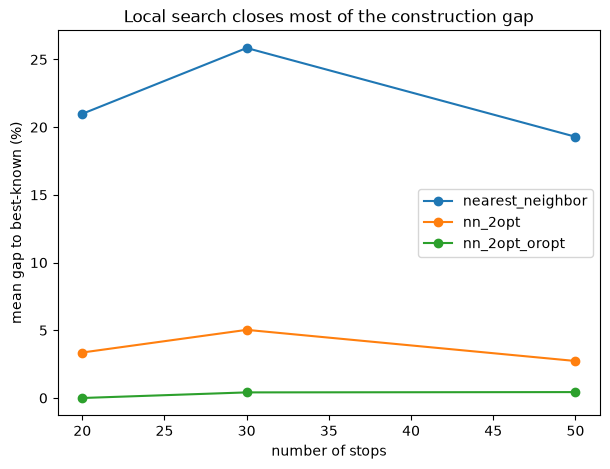

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
for s in stages:
    ax.plot(ladder, [mean_gap[s][n] for n in ladder], "-o", label=s)
ax.set_xlabel("number of stops")
ax.set_ylabel("mean gap to best-known (%)")
ax.set_title("Local search closes most of the construction gap")
ax.legend()
save_figure(fig, "04_gap_vs_size")
plt.show()

## Takeaway

2-opt is the lesson of the whole project in one move: a short loop that uncrosses wasteful edges
turns a mediocre route into a near-optimal one, essentially for free. On a nearest-neighbor start
it lands within a few percent of optimal; or-opt shaves a little more.

Next: **05 · Vehicle Routing** — one vehicle becomes a fleet, with capacities and time windows the
exact MILP cannot touch at scale.